In [7]:
import numpy as np
import matplotlib.pyplot as plt
import random as rand
from scipy.special import erfc
from tqdm import trange

%matplotlib inline

# Prosjekt 2

Diserud, Gaute Oliver & Sanne, Alfred Gilje

## Oppgave 1

### 1a

Diffusjonslikningen er gitt som

$$\begin{equation*}
    \frac{\partial{\phi(x, t)}}{\partial{t}} = D\frac{\partial ^2{\phi(x, t)}}{\partial{x}^2}.
\end{equation*}$$

Ved å fouriertransformere diffusjonslikningen (1) i romlig dimensjon og bruke regneregler for fouriertransformasjonen blir den transformerte likningen

$$\begin{equation*}
    \frac{\partial{\hat{\phi}(\omega, t)}}{\partial{t}} = -\omega^2 D \hat{\phi}(\omega, t).
\end{equation*}$$

Der $\hat{\phi}(\omega, t)$ er den fouriertransformerte av $\phi$. Vil vise at

$$\begin{equation*}
    \phi(x, t) = \frac{1}{\sqrt{4\pi D t}} \int_{-\infty}^\infty h(y)e^{-\frac{(x -y)^2}{4 D t}} dy
\end{equation*}$$

løser diffusjonslikningen, ved å vise at fouriertransformen løser den transformerte likningen. Ved å gjenkjenne likning $\phi(x, t)$ som konvolusjonen over den reelle tallinja mellom $h(x)$ og $g(x, t) = \frac{1}{\sqrt{4\pi D t}}e^{-\frac{(x -y)^2}{4 D t}}$, gir fouriertransformen

$$
\begin{equation*}
    \hat{\phi}(\omega, t) = \widehat{g * h} = \sqrt{2\pi} \hat{h}(\omega)\hat{g}(\omega, t) = \hat{h}(\omega) e^{-\omega^2 D t}.
\end{equation*}$$

Der $\widehat{g * h}$ er fouriertransformen av konvolusjonen mellom g og h og $\hat{g}$ og $\hat{h}$ er transformene til henholdsvis g og h. Ved å ta den tidsderiverte av $\hat{\phi}$ kan man se at denne løser den transformerte diffusjonslikningen. Ved invers fouriertransformasjon finner man da at $\phi(x,t)$ løser diffusjonslikningen. 

Ved å la $t \to 0$ i finner man
$$\begin{equation*}
    \lim_{t \to 0}{e^{-\omega^2 D t}} = 1 \Rightarrow \lim_{t\to 0} \hat{\phi}(\omega, t) = \hat{h}(\omega).
\end{equation*}$$
Dermed kan man se på h som initialbetingelsen til systemet, ettersom $\phi(x, 0) = h(x)$ gir fordelingen av partikler ved $t = 0$.

### 1b

Ved antakelse om at sannsynligheten for at en gitt partikkel befinner seg i en posisjon $x$ i et gitt potensial $V(x)$ er gitt som
$$
\begin{equation*}
    P(x) = \frac{e^{-\beta V(x)}}{Z},
\end{equation*}$$

der $Z$ er partisjonsfunksjonen, og $\beta = k_b T$, temperatur $T$, og boltzmannkonstanten $k_b$. For en partikkel som opphold seg i posisjon $x_0$ og som går til én av tre posisjoner $x \in \{x_0 -1, x_0, x_0 + 1 \}$, med respektive sannsynligheter $\{p^-, p^0, p^+\}$ har vi $p^- + p^0 + p^+  =1$. Ettersom én av de tre mulighetene må skje. Dersom sannsynlighetene er proposjonable med fordelingen $P(x)$, kan vi løse for partisjonsfunksjonen for dette tilfellet.
$$
\begin{align*}
    & 1 = p^- + p^0 +p^+&,\\
    \Rightarrow  & 1 =  P(x_0-1) +P(x_0)  +P(x_0 +1)&,\\
    \Rightarrow & Z =  e^{-\beta V(x_0-1)} + e^{-\beta V(x_0)} + e^{-\beta V(x_0+1)}&.
\end{align*}$$

Satt tilbake inn i sannsynlighetene gir dette
$$
\begin{align*}
\begin{split}
    & p^+ = \frac{1}{1 + e^{-\beta\left[V(x_0 - 1) - V(x_0 +1) \right]} + e^{-\beta\left[V(x_0) - V(x_0 +1) \right]}}, \\
    & p^0 = \frac{1}{1 + e^{-\beta\left[V(x_0 - 1) - V(x_0) \right]} + e^{-\beta\left[V(x_0 + 1) - V(x_0) \right]}}, \\
    & p^- = \frac{1}{1 + e^{-\beta\left[V(x_0) - V(x_0 -1) \right]} + e^{-\beta\left[V(x_0 +1) - V(x_0 -1) \right]}}.
\end{split}
\end{align*}$$

### 1c

Dersom
$$\begin{align*}
    & k_bT \gg |V(x+1) - V(x)|  & \forall x \in \mathbb{R}&\text{, eller} \\
    & k_bT \ll |V(x+1) - V(x)|  & \forall x \in \mathbb{R}&,
\end{align*}$$
følger det av middelverdisetningen at $V(x)$ må være en monoton funksjon, og at tilsvarende må holde for 
$$\begin{equation*}
    |V(x+1) - V(x-1)|.
\end{equation*}$$
Insatt for $\beta = k_b T$, og med hensyn på at $k_bT$ er positivt finner man
$$\begin{align*}
    1 \gg \beta |V(x+1) - V(x)| \Rightarrow & e^{-\beta\left[V(x + 1) - V(x)\right]} \\
    \approx & e^{-\beta\left[V(x - 1) - V(x)\right]} \\
    \approx  & e^{-\beta\left[V(x + 1) - V(x -1)\right]} \\
    \approx  & e^{-\beta\left[V(x - 1) - V(x +1)\right]} \\
    \approx & 1 & \forall x,
\end{align*}$$
slik at alle sannsynligheten vil være tilværmet like, i tilfellet der temperaturen er forholdsvis mye større en potensialgradienten. I det motsatte tilfellet tilfellet vil negativ gradient føre til stor sannsynlighet for å gå til venstre, og positiv gradient vil føre til stor sannsynlighet for å gå til høyre, altså gå mot lavere potensial. Eksempelvis for postitiv gradient $k_b T \ll V(x+1) - V(x)$ vil eksponentialutrykkene i $p^-$ bli forsvinnende små slik at denne sannsynligheten er nesten, mens eksponentialutrykk i de andre sannsynklighetene vil gå mot uendelig, slik at disse sannsynlighetene blir forsvinnende små. Reelle potensial vil naturligvis også ha lokale ektremalpunkt, og det følger at partikler samles opp i lokale minimum.

Fysisk sett betyr dette at for høye temperaturer relativt til potensialgradient tar diffusjon overhånd, og man kan ignorere potensialet, eller betrakte det som konstant. I det motsatte tilfellet vil man for lave temperaturer relativt til potensialgradienten kunne gå ut ifra at partiklene vil gå mot potensialets minima, og se bort i fra statisktiske effekter.

## Oppgave 2

In [ ]:
# Konstanter
beta=1 # Ikke nødvendig å inkludere k setter bare beta lik 1
h=1
max_t=100
num_par=101

Her har vi definert sannsynlighets utrykkene. Trenger ikke den siste fordi sannsynlighetene skal summeres til 1. 

In [ ]:
def pp(x,V):
    p = 1/(1+np.exp(-beta*(V(x-1)-V(x+1)))+np.exp(-beta*(V(x)-V(x+1))))
    return p
    
def pm(x,V):
    p = 1/(1+np.exp(-beta*(V(x+1)-V(x-1)))+np.exp(-beta*(V(x)-V(x-1))))
    return p

Her tar random_step funksjonen inn en partikkel posisjon og bestemmer om den beveger seg til venstre eller høyre. 

In [ ]:
def random_step(x,h,V):
    r= rand.random()
    if (r<pm(x,V)):
        return -1
    elif (r>1-pp(x,V)):
        return 1
    else:
        return 0

In [ ]:
def simulation(start_pos,max_t,h, V):
    pos=np.array(start_pos)
    for i in range(max_t):
        for j in range(0,np.size(pos)):
            pos[j]+=random_step(pos[j],h,V)
    return pos

def multiSim(N,start_pos,max_t,h, V):
    totPos=np.array([])
    for i in range(N):
        pos = simulation(start_pos,max_t,h, V)
        totPos=np.concat((totPos,pos))
    return totPos

### oppgave 2a

 i)

In [ ]:
def V(x):
    return 1
start_pos=np.arange(-50,51,h)
posisjoner_ai= multiSim(100,start_pos,max_t,h,V)


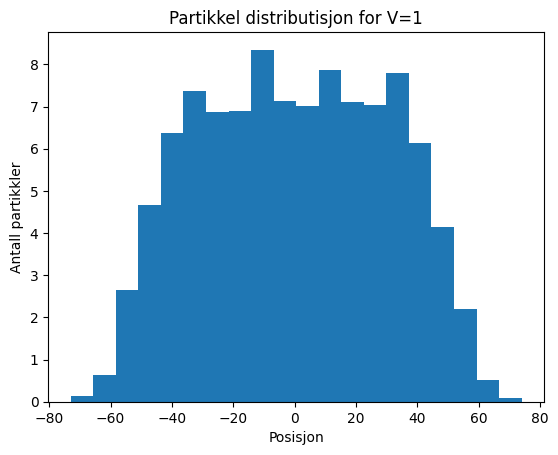

In [ ]:

plt.figure("partikkel distributisjon")
plt.hist(posisjoner_ai,bins=20, weights= [1/100 for x in range(100*101)])
plt.title("Partikkel distributisjon for V=1")
plt.xlabel("Posisjon")
plt.ylabel("Antall partikkler")
plt.show()

Når potensialet er konstant vil partiklene ha like stor sannsynlighet for bevegelse begge retninger. Et resultat av det er at sannsynlighetsfordelingen til en enkelt partikkel vil ligne en normalfordeling med forventningsverdi rundt startposisjonen dens. Summerer du disse sannsynlighetsfordelingene for alle partiklene spredt utover vil det ligne plottet vårt. Det blir en flat topp siden partiklene som ender i en posisjon stort sett bare er de som starter i umidelbar nærhet, og det er det samme for midten som litt lengre ut mot kanten( ikke på kanten).

 ii)

In [ ]:
def V(x):
    return -x
start_pos=np.arange(-50,51,h)
posisjoner_aii= multiSim(100,start_pos,max_t,h,V)

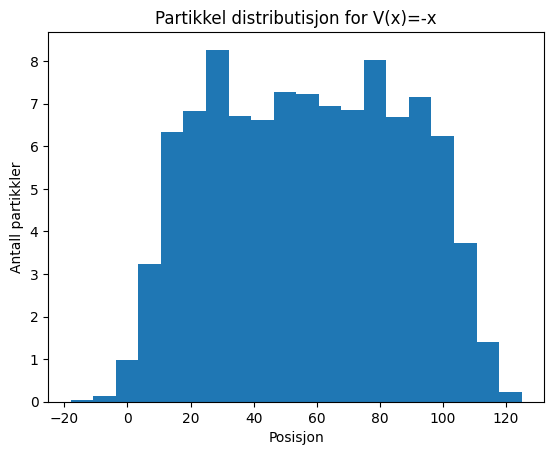

In [ ]:
plt.figure("partikkel distributisjon")
plt.hist(posisjoner_aii,bins=20, weights= [1/100 for x in range(100*101)])
plt.title("Partikkel distributisjon for V(x)=-x")
plt.xlabel("Posisjon")
plt.ylabel("Antall partikkler")
plt.show()

Fordelingen for $V(x) = x$ ligner veldig på fordelingen i 2ai, men vil i stede være sentrert rundt ca posisjon 60. Dette kommer av at når det er mer sannsynlig at partikkelen beveger seg mot høyre vil sannsynlighetsfordelingen til en enkelt partikkel hver sentrert rundt et punkt til høyre for startposisjonen sin avhengig av forskjellen mellom sannsynlighetene for å gå mot høyre og venstre. 

### Oppgave 2b

Må omdefinere random_step og simulation funksjonen for å inkludere partikkelinteraksjon ellers brukes den helt samme koden.

In [ ]:
def random_step(XX,ind,h,V):
    r= rand.random()
    if (r<pm(XX[ind],V) and not((XX[ind]-h) in XX)): # Her inkluderes at partikkelen ikke ta samme posisjons verdi som en annen partikkel
        return -h
    elif (r>1-pp(XX[ind],V) and not((XX[ind]+h) in XX)):
        return h
    else:
        return 0

def simulation(start_pos,max_t,h,V):
    pos=np.array(start_pos)
    for i in range(0,max_t):
        for j in range(0,np.size(pos)):
            pos[j]=pos[j]+random_step(pos,j,h,V)
    return pos


i)

In [ ]:
def V(x):
    return 1
start_pos=np.arange(-50,51,h)
posisjoner_bi= multiSim(100,start_pos,max_t,h,V)

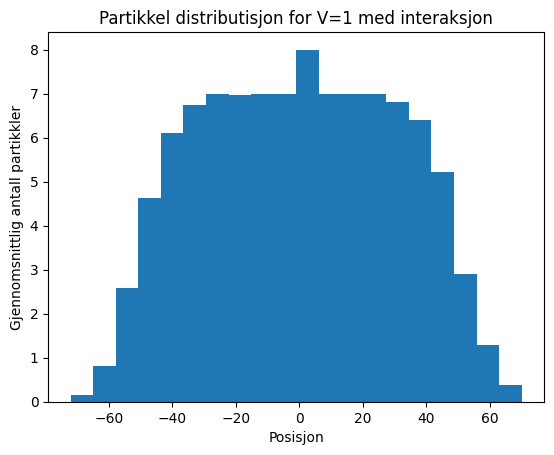

In [ ]:

plt.figure("partikkel distributisjon")
plt.hist(posisjoner_bi,bins=20, weights= [1/100 for x in range(100*101)])
plt.title("Partikkel distributisjon for V=1 med interaksjon")
plt.xlabel("Posisjon")
plt.ylabel("Gjennomsnittlig antall partikkler")
plt.show()

Ligner veldig på fordelingen i 2ai, men med partikkelinteraksjon blir fordelingen enda flatere på midten. Dette har med å gjøre at i motsetning til fordelingen uten partikkelinteraksjon skjer det faktisk veldig lite i midten. Uten partikkelinteraksjon var det at sannsynligheten bestemte at de fleste partiklene var fordelt i midten, med partikkelinteraksjon er det bare det at partiklene i midten ikke beveger seg. På kanten derimot oppfører det seg veldig lignende, siden der skjer det mindre partikkelinteraksjon etterhvert som partiklene spres litt. Dette sammen gjør at fordelingen i 2ai og 2bi blir veldig like, selv om det underliggende som skjer ikke er så likt.

Toppen rundt null er fordi det er 20 bins, så da velger bare histogramet et av binsene rundt null og legger partikkelen rundt null i. 

ii)

In [ ]:
def V(x):
    return -x
start_pos=np.arange(-50,51,h)
posisjoner_bii= multiSim(100,start_pos,max_t,h,V)

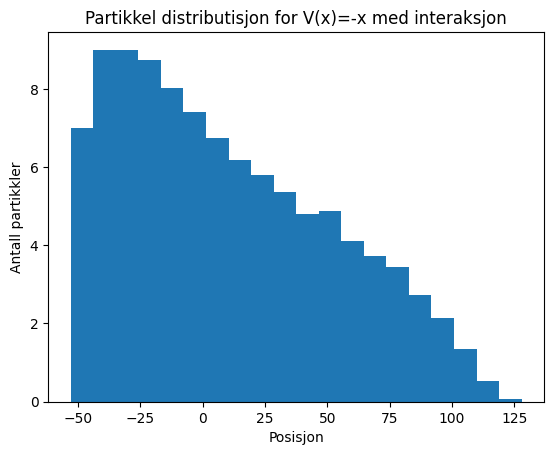

In [ ]:
plt.figure("partikkel distributisjon")
plt.hist(posisjoner_bii,bins=20, weights= [1/100 for x in range(100*101)])
plt.title("Partikkel distributisjon for V(x)=-x med interaksjon")
plt.xlabel("Posisjon")
plt.ylabel("Antall partikkler")
plt.show()


Fordelingen for $V(x)=-x$ med partikkelinteraksjon, blir veldig ulik den med samme potensial men uten partikkelinteraksjon. Dette kommer av at partikkelen neste lengst mot høyre må vente et tidsteg før den kommer seg mot høyre siden den blir blokkert av den ytterste partikkelen, og videre selv blokkerer den innenfor seg i to tidsteg, osv innover. Dette gjør at partikkelene langt mot venstre ikke rekker å bevege seg, siden det er 101 partikler og bare 100 tidsteg. Hadde vi gjort simuleringen med flere tidsteg hadde til slutt fordelingen blitt ganske flat siden partiklene hadde kommet langt nok fra hverandre til at situasjonen ligner mer den i 2aii. 

### Oppgave 2c

For V konstant har temperatur ingenting å si fordi eksponential leddene uansett blir 1, og alle sannsynlighetene blir $\frac{1}{3}$. For V(x)=x vil lavere temperatur, altså høyere $\beta$ bety at eksponential leddene ha større betyding, så potensialet bestemmer i større grad hvor partiklene beveger seg. Det betyr at partiklene i 2a og 2b hadde kommet seg enda lengre i retning minste potensial. I både 2a og 2b ville fordelingen bli veldig flat, ettersom partiklene nesten alltid hadde beveget seg mot høyre, og dermed hadde endt opp nesten samme sted hver gang. Forskjellen hadde vært at fordelingen i 2b hadde fortsatt vært mer spredt av samme grunn som forklart i 2bii.

## Oppgave 3

Starter med å introdusere generaliserte funksjoner for bruk i oppgave 3. Merk at selv om diskusjon i 1c, gjør at man med god tilnærming kan tilnærme partiklene vil følge den negative gradienten til potensialet, og neglisjere statistiske effekter for store verdier av $k \beta$ er dette ikke implementert. Selv om dette ville kunne gi høyere ytelse ville dette stride mot hensikten til oppgaven, ettersom formålet er å se hvordan disse faktorene påvirker resultatet, og ikke rask kjørehastighet.

Videre er også $\beta$ trukket inn i konstanten $k$, for enkelhets skyld, siden $k \beta$ opptrer som konstant i alle oppgavene, og potensialene avhenger lineært av k. For enkelhetskyld er funksjonene definert på en slik måte at ikke-spesifiserte parametre settes lik parameterne i oppgave 3a, med $\alpha = 0.8$. Der gloable variabler kun benyttes innefor sin kodeblokk, eller tilsvarer lokale variabler er variabelnavn gjenbrukt, mens de som benyttes i flere kodedblokker er markert med oppgavenummer. Der oppgaven spesifiserer at det skal brukes verdier som er jevnt fordelt mellom to verdier, er det lagt vekt på at punktene skal være jevnt fordelt, der hvor tallverdiene oppgitt i utgangspunktet ville ført til flyttall for heltallsvariable slik som $T_p$ dersom man inkluderer begge endepunkt.

In [ ]:
def V_1(
        x : np.ArrayLike,
        k : float       = 1000,
        N_x : float     = 100,
        alpha : float   = 0.8
        ) -> np.ArrayLike : 
    """
    params:
        x:      Arraylike med heltallsposisjoner
        k:      konstant som tilsvarer k * beta
        N_x:    antall binding sites i én periode
        alpha:  konstant
    return:
        pot:    Potentialet V_1
    """
    x_modN =x%N_x

    pot = -k*(x_modN-N_x)/((1 - alpha)*N_x)
    pot[x_modN <= alpha * N_x]  =(k * x_modN/(alpha * N_x))[x_modN <= alpha * N_x]

    return pot
    
def V_2(x, *args) -> int:
    return np.zeros_like(x)

def probabilities(
        V : function,
        x_0 : np.ArrayLike,
        k : float,
        N_x : float,
        alpha : float
        ) -> tuple[np.ndarray, np.ndarray] : 
    """
    params:
        V:    potensialfunksjonen sannsynlighetene beregnes ut ifra
        x_0:      ArrayLike med posisjoner, hvis sannsynlighet for forflyttning skal finnes
        *args:  parameterene som potensialet tar inn
    returns:
        
    """

    pot_minus = V(x_0 - 1, k, N_x, alpha)
    pot_zero  = V(x_0, k, N_x, alpha)
    pot_plus  = V(x_0 + 1, k, N_x, alpha)

    p_minus = (1 + np.exp(pot_minus - pot_plus) + np.exp(pot_minus - pot_zero))**-1
    p_plus = (1 + np.exp(pot_plus - pot_zero) + np.exp(pot_plus - pot_minus))**-1
    
    return p_minus, p_plus

def random_step(x,pm,pp,*args):
    r =

def simulate3(
        startPositions : np.ndarray = np.array([]),
        alpha : float  = 0.8, 
        T_p : int = 500, 
        N_x : int = 100, 
        N_p : int = 1200,
        k : int  = 1000,
        b = 3,
        spatialPeriods : int  = 2,
        cycles : int = 10,
        startV_2 : bool = False
        )-> tuple[np.ndarray, np.ndarray, list]:
    """
    params:
        startPositions: array over startposisjoner, hvis None brukes fylles alle posisjoner
        alpha: konstant, forskyver potensialet
        T_p: tidsperiode for en halv syklus
        N_x: romlig periode for potensial
        N_p antall partikler, rundes av til multiplum av antall festepunkter
        k: samlet konstant lik k * beta
        spatialPeriods: antall romlige perioder, gir antall festepunkter som N_p * spatialPeriods
        cycles: antall sykluser som skal simuleres
        startV_2: hvis True starter blir V_2 det første potensialet
        random_step: stegfunksjon som finner neste posisjonsarray basert på input
    returns:
        x: array med sluttposisjoner
        currents: array
        XX: matrise med posisjoner for hvert tidssteg slik at x(t) = X[t]
    """

    h = 1
    N = N_x * spatialPeriods #antall festepunkter
    XX = [] 
    x_ref : np.ndarray  = np.arange(N) #referansearray for x-aksen. Verdier samsvarer med indeks for referansearrayer
    
    if len(startPositions) == 0:
        startPositions = x_ref

    x_0 : np.ndarray = np.asarray([i for i in startPositions for _ in range(N_p//len(startPositions))]) #array med alle partikler
    XX.append(x_0)

    p_1 = probabilities(V_1, x_ref, k, N_x, alpha)
    p_2 = probabilities(V_2, x_ref, k, N_x , alpha)

    pm_tup = (p_1[0], p_2[0])
    pp_tup = (p_1[1], p_2[1])

    n = np.zeros_like(x_0)

    currents = np.zeros(cycles)
    for c in trange(2 * cycles, ascii = True, desc  = "runnning half-cycles"):
        pm_ref  = pm_tup[c%2 - int(startV_2)]
        pp_ref =  pp_tup[c%2 - int(startV_2)]

        for t in range(T_p):
            x = x_0%N
            pm = np.asarray([pm_ref[i] for i in x]) # sannsynlighet for å gå til venstre for alle partikler
            pp = np.asarray([pp_ref[i] for i in x]) # sannsynlighet fro å gå til høyre for alle partikler

            random_step(x,pm,pp,N_x,spatialPeriods,b,h)

            n += x - x_0%N
            x_0 = x

            XX.append(x_0)
            
        if c%2:
            currents[c//2] = np.mean(n)/(2 * T_p)
            n = np.zeros_like(x)

    return x, currents, XX


### 3a

simulering med $\alpha = 0.8$.

In [ ]:
x, currentsA1, XX = simulate3(alpha = 0.8)

for i in range(len(currentsA1)):
    print(f"{i}: {currentsA1[i]:.6f}")

runnning half-cycles: 100%|##########| 20/20 [00:04<00:00,  4.38it/s]

0: -0.028928
1: -0.013468
2: -0.013417
3: -0.013537
4: -0.014078
5: -0.011901
6: -0.012071
7: -0.013014
8: -0.013645
9: -0.013461


Man får netto strøm mot venstre ettersom partiklene samles opp i minimumspunktene til $V_1$, og deretter blir eksitert til tilstand $V_2$, hvor de diffunderer. Ettersom nærmeste lokale maksimum for partiklene er det til venstre for der de ble samlet opp, er det flere partikler som forflytter seg forbi dette, enn det er partikler som forflytter seg forbi nærmeste lokale maksimum mot høyre. Når de deeksiteres vil disse partiklene samles opp i et annet lokalt minimum, noe som fører til netto strøm.

Dette forklarer hvorfor strømmen er større til å start med, ettersom de da var uniformt fordelt, og ikke fordelt rundt minimumspunktene slik som i resten av syklusene.

In [ ]:
x, currentsA2, XX = simulate3(alpha = 0.1)

for i in range(len(currentsA2)):
    print(f"{i}: {currentsA2[i]:.6f}")

runnning half-cycles: 100%|##########| 20/20 [00:04<00:00,  4.60it/s]

0: 0.039681
1: 0.028422
2: 0.029337
3: 0.029077
4: 0.027093
5: 0.027845
6: 0.029239
7: 0.029165
8: 0.029756
9: 0.027835


For $\alpha = 0.1$ har vi en tilsvarende situasjon, men hvor lokale mimium ligger rett til venstre for lokale maksimum, og man får dermed strøm mot høyre. Det ligger nærmere enn for $\alpha = 0.8$ så derfor er strømmen større.

### 3b

In [ ]:
timePeriodList = [i for i in range(1, 1001, 20)]   
startPositions = np.array([0, 100])
n = len(timePeriodList)
avgCurrentB = np.zeros(n)
N_x = 100

for i in range(n):
    x, currents, XX = simulate3(
        T_p = timePeriodList[i],
        cycles = 1,
        alpha = 0.8,
        N_p = 40 * N_x,
        N_x = N_x,
        startPositions = startPositions,
        startV_2=True)
    
    avgCurrentB[i] = np.mean(currents)

runnning half-cycles: 100%|##########| 2/2 [00:02<00:00,  1.40s/it]


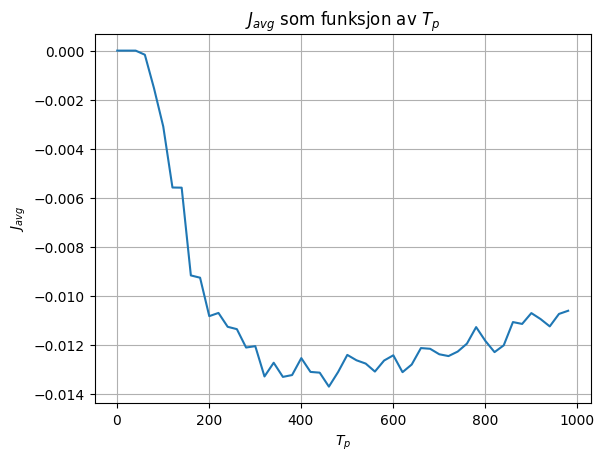

In [ ]:
plt.plot(timePeriodList, avgCurrentB, label = "$k_b \beta = 1000")
plt.title("$J_{avg}$ som funksjon av $T_p$")
plt.xlabel("$T_p$")
plt.ylabel("$J_{avg}$")
plt.grid()
plt.show()

Strømmen mot venstre øker for økende verdier av $T_p$. Dette samvarer med lengre tid for diffusjon, slik at flere partikler beveger forbi nærmeste lokale maksimum for $V_1$. I tillegg vil det for $T_p < \alpha N_x = 80$ ($1-\alpha$ må brukes istedenfor $\alpha$ dersom $\alpha > 0.5$) ikke være nok tid for alle partiklene til å samles i sitt lokale minimumspunkt i løpet av tidsperioden med potensialet $V_1$. Dette gjør strømmen i starten øker rast med økende tidsperiode, ettersom de både diffunderer mer, og forflytter seg lengre etter diffusjon. Når tidsperioden er tilstrekkelig høy, vil partiklene diffundere tregere, ettersom de allerede er utspredt, og alle partiklene vil samles opp i lokale minimumspunkt i løpet av den deeksiterte perioden. Dermed avtar strømmen mot venstre ved økning av $T_p$, ettersom partiklene ikke beveger seg lengre per periode, mens periodene fortsatt blir lengre.



### 3c

Definerer først en funksjon for den analytiske strømmen som funksjon av de ingående variablene, ved hjelp av scipy.special.erfc.

In [ ]:
def analCurrent(
        alpha : np.ndarray,
        N_x : int,
        T_p : np.ArrayLike):
    return N_x/(4*T_p) * (erfc(alpha*N_x/2 * np.sqrt(3/T_p)) - erfc((1-alpha)*N_x/2 * np.sqrt(3/T_p)))

Ettersom den analystiske løsningen baserer seg på at partiklene i utgangspunktet er fordelt som $\delta(x),$ gir det mening å bruke liknende betingelser som i oppgave 3b, hvor partiklene starter samlet og starter i den eksiterte tilstanden med $V(x, t = 0) = V_2(x)$. Kjøretid påvirkes først og fremst av antall partikler i systemet, og strømmen er uavhengig av hvilket loklt mimimum partiklene starter i, så andre variabler som ikke er spesifisert i oppgaven kan velges ganske fritt. Velger liknende som i tidligere oppgaver for enkelhets skyld.

In [ ]:
n = 50

alphaArr = np.linspace(0.001, 0.999, n) 
startPositions = np.array([0, 100])
avgCurrentC = np.zeros(n)

for i in range(n):
    x, currents, XX = simulate3(
        T_p = 500,
        cycles = 1,
        alpha = alphaArr[i],
        N_x  = 100,
        N_p = 1200,
        k = 1000,
        startPositions = startPositions,
        startV_2=True)
        
    avgCurrentC[i] = np.mean(currents)

C:\Users\alfre\AppData\Local\Temp\ipykernel_3548\3096212017.py:46: RuntimeWarning: overflow encountered in exp
  p_minus = (1 + np.exp(pot_minus - pot_plus) + np.exp(pot_minus - pot_zero))**-1
runnning half-cycles: 100%|##########| 2/2 [00:00<00:00,  4.85it/s]
C:\Users\alfre\AppData\Local\Temp\ipykernel_3548\3096212017.py:47: RuntimeWarning: overflow encountered in exp
  p_plus = (1 + np.exp(pot_plus - pot_zero) + np.exp(pot_plus - pot_minus))**-1
runnning half-cycles: 100%|##########| 2/2 [00:00<00:00,  4.51it/s]


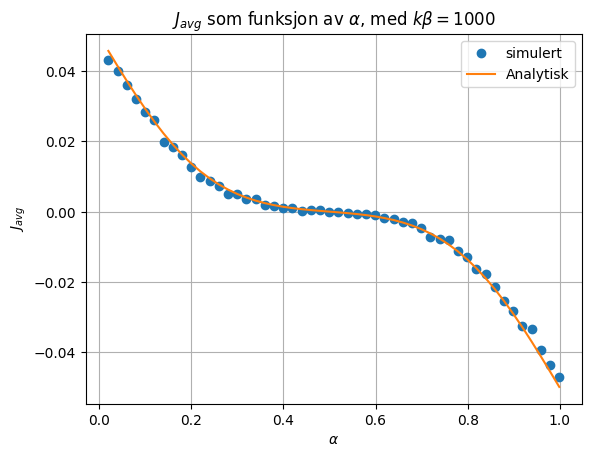

In [ ]:
avgAnalCurrentC = analCurrent(alphaArr, N_x = 100, T_p = 500)

plt.figure()
plt.plot(alphaArr, avgCurrentC, 'o', label = "simulert")
plt.plot(alphaArr, avgAnalCurrentC, label = "Analytisk")
plt.grid()
plt.legend()
plt.title("$J_{avg}$ som funksjon av $\\alpha$, med $k\\beta = 1000$")
plt.xlabel("$\\alpha$")
plt.ylabel("$J_{avg}$")
plt.show()

Liten $\alpha$ gir strøm mot høyre, og stor $\alpha$ gir strøm mot venstre. Der strømmen varierer mer lenger vekk ifra $\alpha = 0.5$. Dette skyldes at partiklene diffunderer mest der de er konsentrert slik at flere partikler diffunderer forbi lokalt makismum dersom det ligger nærmere korresponderende lokalt mimium, som er utgangspunktet før diffusjon. På liknende måte vil forskyving av normalfordelingen med tanke på maksiumspunktet ha mer å si nærmere punktet, ettersom er normalfordelingen har høyere tetthet nær sentrum. Ser at de to ulike løsningene er koherente.

### 3d

In [ ]:
n = 50
kArr = np.array([0.01, 1, 2, 3, 5, 10])
m = len(kArr)

N_x = 100
N_p = 12 * N_x
T_p = 500


alphaArr = np.linspace(0.001, 0.999, n)
startPositions = np.array([0, 100])
avgCurrentD = np.zeros((m, n))

for i in range(n):
    for j in range(m):
        x, currents, XX = simulate3(
            T_p = T_p,
            cycles = 1,
            alpha = alphaArr[i],
            N_x  = N_x,
            N_p = N_p,
            k = kArr[j],
            startPositions = startPositions,
            startV_2=True)
        
        avgCurrentD[j][i] = np.mean(currents)

C:\Users\alfre\AppData\Local\Temp\ipykernel_3548\3096212017.py:18: RuntimeWarning: divide by zero encountered in divide
  pot = -k*(x_modN-N_x)/((1 - alpha)*N_x)
runnning half-cycles: 100%|##########| 2/2 [00:00<00:00,  4.63it/s]


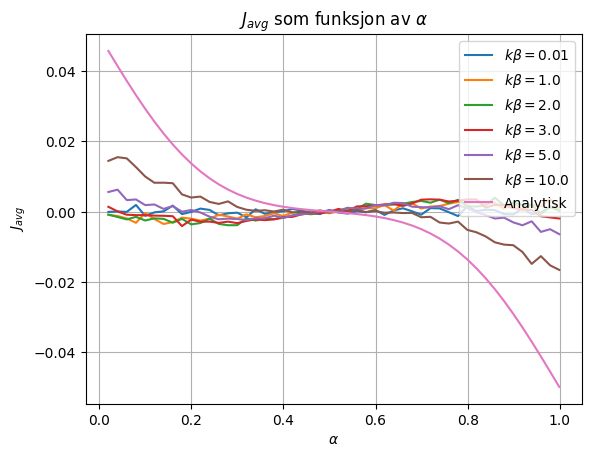

In [ ]:
avgAnalCurrentD = analCurrent(alphaArr, N_x = 100, T_p = 500)

plt.figure()
for j in range(m):
    plt.plot(alphaArr, avgCurrentD[j], label = f"$k \\beta = {kArr[j]}$")
plt.plot(alphaArr, avgAnalCurrentD, label = "Analytisk")
plt.grid()
plt.legend(loc = "upper right")
plt.title("$J_{avg}$ som funksjon av $\\alpha$")
plt.xlabel("$\\alpha$")
plt.ylabel("$J_{avg}$")
plt.show()

Alle verdiene for $k \beta$ gir stort avik fra den analytiske løsningen, og dette skyldes nok at potensialgradientet ikke er bratt nok for at antakelsen om at alle partiklene ender opp i potensialminima er gyldig.

For $k \beta = 0.01$ er det i praksis kun diffusjon som spiller en rolle for begge potensialene ettersom den termiske energien er mye større enn potensialgradienten. Dermed skyldes variasjonene i strøm trolig kun støy.

For $k \beta \in {1,2,3}$ får man en svak strøm i motsatt retning av den predikert av den analytiske løsningen. Grunnen til dette er at i disse tilfellene har partiklenes posisjoner mindre å si, ettersom det er brattheten til potensialene som har mer å si for hvor langt partiklene beveger seg, og den bratteste potensialgradienten fører partiklene i motsatt retning av den predikerte strømmen, mens den slake potensialgradienten ikke påvirker partiklene nok, selv om den har flere partikler på seg.

For $k \beta = 5,10$ går strømmen igjen i riktig retning, som tyder på at det ved høyere verdier for $T_p$ trolig vil være nærmere den analytsike løsningen, men at tidsperioden ikke er stor nok til at partiklene rekker å samles, eller at de ikke sentreres fullstendig i mimimumspunktet.

### 3e

Velger å ta gjennomsnittet over 10 tidsykluser, siden parameterene gitt i oppgaven gir veldig varierende målinger som er vanskelige og tolke, og koden er rask nok. Ettersom $T_p \gg \alpha N_x$ og $k \beta = 1000$ tar koden under utganspunkt i at partiklene ender opp i lokale minimum etter hver syklus, for å slippe å tilbakestille partiklene for hver syklus.

In [ ]:
timePeriodList = [i for i in range(80, 1500, 71)]   
startPositions = np.array([0, 100])
n = len(timePeriodList)
avgCurrentE = np.zeros(n)
N_x = 10
print(f"n = {n}")

for i in range(n):
    x, currents, XX = simulate3(
        T_p = timePeriodList[i],
        cycles = 10,
        alpha = 0.8,
        N_p = 40*N_x,
        N_x = N_x,
        startPositions = startPositions,
        startV_2=True)
    
    avgCurrentE[i] = np.mean(currents)

C:\Users\alfre\AppData\Local\Temp\ipykernel_3548\3096212017.py:46: RuntimeWarning: overflow encountered in exp
  p_minus = (1 + np.exp(pot_minus - pot_plus) + np.exp(pot_minus - pot_zero))**-1


n = 20


runnning half-cycles: 100%|##########| 20/20 [00:04<00:00,  4.02it/s]


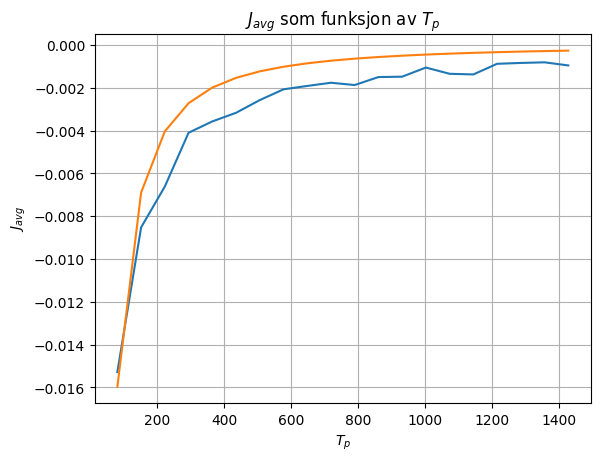

In [ ]:
avgAnalCurrentE  = analCurrent(alpha = 0.8, N_x = 10, T_p = np.array(timePeriodList))

plt.plot(timePeriodList, avgCurrentE)
plt.plot(timePeriodList, avgAnalCurrentE)
plt.title("$J_{avg}$ som funksjon av $T_p$")
plt.xlabel("$T_p$")
plt.ylabel("$J_{avg}$")
plt.grid()
plt.show()

Den analytiske løsningen gir en god tilnærming for lave verdier $T_p$, men går raskere mot null en simulerte løsningen.Analytisk antas litt forenklet at man maksimalt kan få en strøm der partiklene flytter seg $N_x$ posisjoner i én retning per syklus, uvahengig av lengden på tidsperioden. For modellen vår vil partiklene derimot kunne diffundere over flere tidsperioder før de deeksiteres, og strømmen vil dermed gå saktere mot null. Dette fordi det fører til at sentreringen av fordelingen har mer å si.

### 3f
Ettersom den analytiske funksjonen tar utgangspunkt i et uendelig antall partikler, vil partiklene være fordelt etter sannsynlighetsfordelingen, mens det med et endelig antall partikler vil kunne variere hvor mange partikler som havner på hver sin side av et lokalt maksimum. Dette er mer sannsynlig for små/store $\alpha$, ettersom det er flere partikler i nærheten av lokale maksimum for slike $\alpha$. 

Dersom $k \beta$ eller $T_p$ i forhold til $N_x$ ikke er store nok til at alle partiklene rekker å nå sine lokale minimum innen tidsperioden for $V_1$ er omme, vil dette kunne gi store avvik for strømmen, ettersom den analytiske løsningen baserer seg på at alle partiklene beveger seg til sitt lokale minimum. For $k \beta < \infty$  vil det også være en endelig sannsynlighet for at partiklene ikke befinner seg nøyaktig i minimumspunktet etter endt tidsperiode, siden $p_-,p_+ > 0$. Dette gir neppe store avvik fra den analytiske løsningen for tilstrekkelig stor $k\beta$ ettersom dette gjelder få partikler, med lite avvik i posisjon, men kan gi forskyving av hvor partiklene sentreres for små verdier av $k \beta$, grunnet ulik bratthet, og kan også føre til strøm i motsatt retning dersom den ene retningen er tilstrekkelig bratt i forhold til den andre, og tidsperioden ikke er lang nok til at partiklene senterers i begge retninger.

Videre antar en analytiske løsningen at én gitt partikkel aldri beveger seg mer enn $N_x$ til høyre eller venstre i løpet av en periode. Dette fører til at ved nok utspredning av partikkler får man netto null strøm, ettersom nesten alle partiklene har beveget seg eneten til høyre eller venstre. I realiteten kan partiklene bevege seg over flere perioder, og vil fortsette å være sentrert mer mot én side. Slik vil netto forflytning ikke gå mot null slik som det analytiske tilfellet. Ettersom strøm er nettoforflytning per tid, vil dette også gi høyere strøm. 

# Oppgave 4
Først for at koden fra oppgave 3 skulle funke for oppgave 4, måtte vi gjør en liten justering. Stort sett innbar det kun å legge til denne random_step funksjonen som er definert under. Den tar inn arrayet med posisjonene for et tidsteg og gjør random walk simuleringen for et tidsteg. I tillegg, som ønsket, sørger den for at partiklene ikke koliderer. Dette kommer fra leddene etter and i if setningen. I tillegg trengtes det å redfinere simulate funksjonen litt for at den skal kunne ta inn b.

In [ ]:
def random_step(x,pm,pp,N_x,spatialPeriods,b,h):
    length=len(x)
    #Lager et array med tilfeldige tall for å avgjøre hvilken retning
    r=np.random.rand(length)

    #Lager et array med indexer for x i en tilfeldig rekkefølge
    idx=np.arange(0,length,1)
    np.random.shuffle(idx)
    
    for i in idx:
        if (r[i]<pm[i] and b+h<=abs(x[i]-x[i-1])<=N_x*spatialPeriods-b-h): # Sjekker steg retning og at bevegelse ikke gir kollisjon
            x[i]-=1
        elif (r[i]>(1-pp[i]) and b+h<=abs(x[i-length+1]-x[i])<=N_x*spatialPeriods-b-h):
            x[i]+=1
    return x

In [ ]:

def simulate4(
        startPositions : np.ndarray = np.arange(200),
        alpha : float  = 0.8, 
        T_p : int = 500, 
        N_x : int = 100, 
        N_p : int = 1200,
        k : int  = 1000,
        b : int = 4,
        h: int = 1,
        spatialPeriods : int  = 2,
        cycles : int = 10,
        startV_2 : bool = False,
        random_step : function,
        )-> tuple[np.ndarray, np.ndarray, list]:
    """
    params:
        startPositions: array over startposisjoner
        alpha: konstant, forskyver potensialet
        T_p: tidsperiode for en halv syklus
        N_x: romlig periode for potensial
        N_p antall partikler, rundes av til multiplum av antall festepunkter
        k: samlet konstant lik k * beta
        spatialPeriods: antall romlige perioder, gir antall festepunkter som N_p * spatialPeriods
        cycles: antall sykler som skal simuleres
        startV_2: hvis True starter blir V_2 det første potensialet
    returns:
        x: array med sluttposisjoner
        currents: array
        XX: matrise med posisjoner for hvert tidssteg slik at x(t) = X[t]
    """

    
    N = N_x * spatialPeriods #antall festepunkter
    XX = [] 
    x_ref : np.ndarray  = np.arange(N) #referansearray for x-aksen. Verdier samsvarer med indeks for referansearrayer
    

    x_0 : np.ndarray = np.asarray([i for i in startPositions for _ in range(N_p//len(startPositions))]) #array med alle partikler
    XX.append(x_0)

    p_1 = probabilities(V_1, x_ref, k, N_x, alpha)
    p_2 = probabilities(V_2, x_ref, k, N_x , alpha)

    pm_tup = (p_1[0], p_2[0])
    pp_tup = (p_1[1], p_2[1])

    n = np.zeros_like(x_0)

    currents = np.zeros(cycles)
    for c in trange(2 * cycles, ascii = True, desc  = "runnning half-cycles"):
        pm_ref  = pm_tup[c%2 - int(startV_2)]
        pp_ref =  pp_tup[c%2 - int(startV_2)]

        for t in range(T_p):
            x = x_0%N
            pm = np.asarray([pm_ref[i] for i in x])
            pp = np.asarray([pp_ref[i] for i in x])

            ## Den eneste delen som er endre fra oppgave 3
            random_step(x,pm,pp,N_x,spatialPeriods,b,h)    ## Her gjør utføres random step simulering med partikkelinteraksjon

            n += x - x_0%N
            x_0 = x

            XX.append(x_0)
            
        if c%2:
            currents[c//2] = np.mean(n)/(2 * T_p*N_p)
            n = np.zeros_like(x)

    return x, currents, XX

### 4a

Her defineres størrelsene som er presisert i oppgaven. 

In [ ]:
alpha  = 0.2
T_p= 50
N_x  = 20
k = 1000
b=3
h=1
spatialPeriods = 4
cycles = 5
startV_2  = True
N_p  = 10

Her kjøres simuleringen for 4a


In [ ]:
startPositions=np.arange(0,N_x*spatialPeriods,int((N_x*spatialPeriods/N_p)//1))
x, currents, XX=simulate4(startPositions,alpha,T_p,N_x,N_p,k,b,h,spatialPeriods,cycles,startV_2) 

runnning half-cycles: 100%|##########| 10/10 [00:00<00:00, 214.50it/s]


Plotter data

Currents=  [0.0074 0.0015 0.0039 0.0031 0.0022]


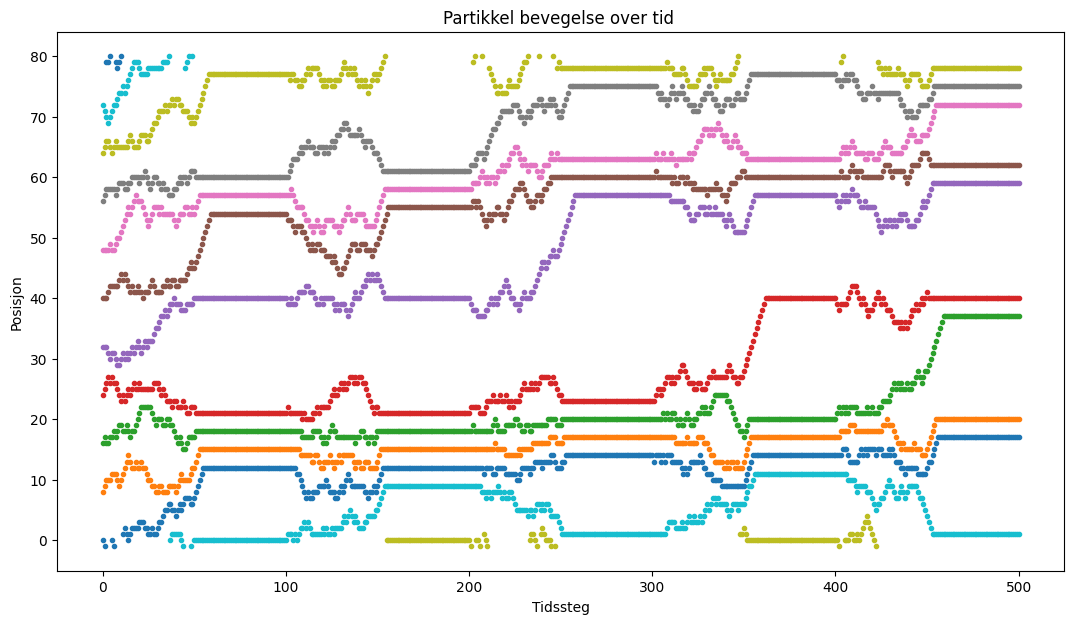

In [ ]:

print("Currents= ",currents)

plt.figure(figsize=(13,7))
XX_tranpose=np.transpose(XX)
for i in range(len(XX_tranpose)):
    plt.plot(XX_tranpose[i],".")
plt.title("Partikkel bevegelse over tid ")
plt.ylabel("Posisjon")
plt.xlabel("Tidssteg")
plt.show()

#### Diskusjon:
Det første vi la merke til er at partiklene har en tendens til å klumpe seg litt mer opp. Så klart så er jo hovedårsaken til oppklumpingen potensialgropene, som er til stede i simulasjonen uten partikkelinteraksjon, men ser en på plottet over så har flere partikler samlet seg i potensialgropen rundt 20. Vår hypotese er at siden partiklene ikke kan pasere hverandre, så er det ikke så usannsynlig at én partikkel blokkerer alle partiklene bak seg og lager en hopning. I eksempelet over vil dette være den røde partikkelen, som i alle syklene blokkerer den grønne partikkelen fra å hoppe i neste potensial grop, og skaper derfor en opphopning.

En annen effekt med partikkelkollisjonen som vi observerte er at det sjeldent er mer enn en partikkel som klarer å hoppe til neste potensialgrop. Ved høyere T_p og flere partikler vil dette så klart skje oftere, men trenden med at det sjeldnere at flere partikler kommer til neste grop er gjennomskuende (ser mer av det i 4b). Dette virker logisk ettersom den ytterste partikkelen vil blokkere den bak, som videre blokker de bak seg igjen. Derfor blir det slik at den andre partikkelen ofte ikke rekker å komme seg til neste grop fordi flere av stegene dens mot neste grop blir blokkert av partikkelen utenfor. 

Derimot så gjør partikkelkollisjon at den ytterste partikkelen oftere klarer å komme seg til neste grop. Dette er grunnet i den samme effekten som nevnt over, der den ytterste partikkelen oftere kommer seg mot neste grop når det konstante potensialet virker, fordi mange av dens steg tilbake blir blokkert av de andre partiklene som var i samme grop som den. Dette gjør at sannsynligheten for at den ytterste partikkelen kommer seg til neste grop er høyere med partikkelkollisjon enn uten. 

### 4b

In [ ]:
# Definerer størrelsene som presisert i oppgaven
alpha  = 0.2
T_p= 300
N_x  = 100 
k = 1000
b=20
h=1
spatialPeriods = 10
cycles = 100
startV_2  = True

Kjører simulasjonen for forskjellige partikkel tettheter mellom 0 og 1

In [ ]:
# Lager et array med forskjellige partikkel antall som tilsvarer tetthet fra 0 til 1
N_p= np.ceil(np.linspace(0,1*N_x*spatialPeriods/b,10))

# lager et array for å lagre data
cur_rho=np.zeros_like(N_p)
rho = N_p*b/spatialPeriods/N_x

# Kjører simuleringen for alle partikkel antall og lagrer gjennomsnittlig strøm i cur_rho
for i in range(len(N_p)):
    startPositions=np.int_(np.floor(np.linspace(0,N_x*spatialPeriods,int(N_p[i]))))
    x, currents, XX=simulate4(startPositions,alpha,T_p,N_x,int(N_p[i]),k,b,h,spatialPeriods,cycles,startV_2)
    cur_rho[i]=np.mean(currents)

runnning half-cycles:   0%|          | 0/200 [00:00<?, ?it/s]c:\Users\godis\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\godis\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
runnning half-cycles: 100%|##########| 200/200 [00:15<00:00, 13.17it/s]


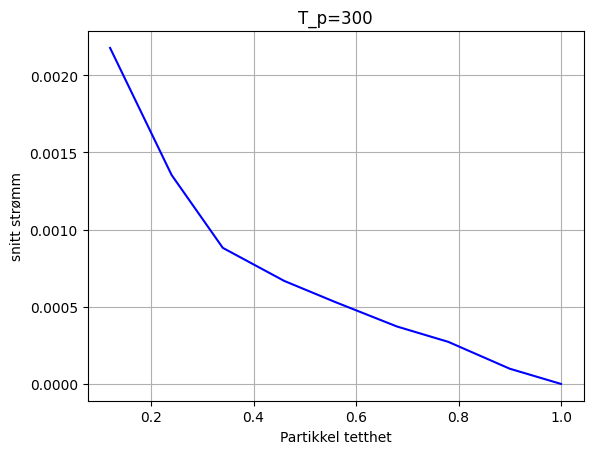

In [ ]:
plt.figure("T_p")
plt.title("T_p=300")
plt.plot(rho,cur_rho, color="blue")
plt.xlabel("Partikkel tetthet")
plt.ylabel("snitt strømm per partikkel")
plt.grid()
plt.show()

#### Diskusjon:
Først ser en at ved veldig høy tetthet blir strømmen veldig lav. Dette er et resultat av partiklene trenger åpne festepunkter å bevege seg til, men siden partikkeltettheten er så høy er det få partikler som har muligheten til å bevege seg. I tillegg er strømmen normalisert for antall partikler slik at den blir enda mindre relativt. Videre ser vi at generelt flere partikler forårsaker mindre partikkelstrøm. Dette kan knyttes til effekten som vi beskrev i 4a der partikkelinteraksjonen gjør at det ofte kun er én partikkel som kommer seg videre, derfor vil middlingen over antall partikler forårsake at flere partikler har mindre strøm. Ser en på absolutt strøm vil litt høyere partikkeltetthet gjøre det bedre enn de laveste, antageligvis på grunn av den andre effekten nevnt tidligere, der sannsynligheten for at én partikkel hopper til neste potensialgrop er høyere når det er noen andre partikler i gropen som stopper den i å bevege seg bakover. 

### 4c

In [ ]:
# Definerer ny lavere T_p
T_p= 150
cycles = int(30000/T_p)

# lager et array for å lagre resultater
cur_rho_lowerT_p=np.zeros_like(N_p)

# Kjører simulering for alle partikkel antall, Samme som i 4b
for i in range(len(N_p)):
    startPositions=np.int_(np.floor(np.linspace(0,N_x*spatialPeriods,int(N_p[i]))))
    x, currents, XX=simulate4(startPositions,alpha,T_p,N_x,int(N_p[i]),k,b,h,spatialPeriods,cycles,startV_2)
    cur_rho_lowerT_p[i]=np.mean(currents)

runnning half-cycles: 100%|##########| 400/400 [00:10<00:00, 36.43it/s]


In [ ]:
# Definerer ny høyere T_p
T_p= 500
cycles = int(30000/T_p)

# lager et array for å lagre resultater
cur_rho_higherT_p=np.zeros_like(rho)

# Kjører simulering for alle partikkel antall, Samme som i 4b
for i in range(len(N_p)):
    startPositions=np.int_(np.floor(np.linspace(0,N_x*spatialPeriods,int(N_p[i]))))
    x, currents, XX=simulate4(startPositions,alpha,T_p,N_x,int(N_p[i]),k,b,h,spatialPeriods,cycles,startV_2)
    cur_rho_higherT_p[i]=np.mean(currents)

runnning half-cycles: 100%|##########| 120/120 [00:09<00:00, 12.64it/s]


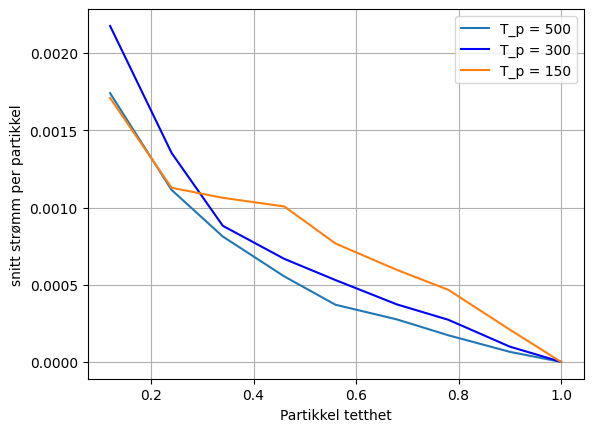

In [ ]:
plt.plot(rho,cur_rho_higherT_p,label="T_p = 500")
plt.plot(rho,cur_rho, label="T_p = 300",color="blue")
plt.plot(rho,cur_rho_lowerT_p,label="T_p = 150")
plt.xlabel("Partikkel tetthet")
plt.ylabel("snitt strømm per partikkel")
plt.grid()
plt.legend()
plt.show()

### Diskusjon:
Totalt ser en to effekter her. For høy tetthet er kortere syklus bedre, men for lav tetthet er både lengre syklus og kortere syklus dårligere. Grunnen til at kortere syklus gir bedre resultat for høy tetthet, kommer igjen fra effekten ved at høy tetthet gir høy sannsynlighet for at én partikkel hopper til neste potensialgrop. Siden det uansett er slik at det sannsynligvis bare er én partikkel som hopper til neste grop per syklus, vil kortere syklus og dermed flere sykluser gi høyere partikkelstrøm. Selvfølgelig vil dette nå én grense der for kort syklus blir værre igjen, men simulering gjør det tydelig at for forskjellige tettheter er forskjellige sykluslengder optimale. 

For lav tetthet er syklus varighet på 200 tidsteg som var best. Dette skyldes at ved lav tetthet vil partikkelinteraksjonen spille mindre rolle, ettersom det skjer oftere, og dermed vil det oppføre seg likere simuleringen uten partikkelinteraksjon. Da handler optimalisering av syklus varighet mer om tiden det tar for sannsynlighetsfordelingen til posisjonen av partikkelen i én grop blir tilstrekkelig fordelt. For kort syklus så blir sannsynligheten fordelingen klumpet rundt utgangsposisjonen, som er i potensialgropen partikkelen befant seg i. Derfor når potensialet bytter tilbake til ratchet potensialet så  rekker ikke partikkelen til neste potensialgrop, og strømmen blir lavere. Ved for lang syklus så vil ikke flere partikler komme til neste strøm, fordi sannsynlighetsfordelingen til partiklene blir tilnærmet konstante over tid etterhvert. Det gjør at den ekstra varigheten til syklusen bare blir en slags ventetid, men som vil slå negativt ut på på strømmen på grunn av middlingen over tid. 

### 4d

![image.png](attachment:image.png)

figur 2a i 

Chacko, J. og Tripathy, G.(2015). Interacting particles in disordered flashing ratchets. Indian Journal of Physics, volum 89, 981–988,  hentet fra http://dx.doi.org/10.1007/s12648-015-0660-5


I denne artikkelen så ser de på nesten det helt samme scenarioet som oss, bare at det også inkluderer litt tilfeldig feil i potensialet. Denne figuren derimot er av før de går videre til det de kaller "Disordered flashing rachets". Her plotter det nesten nøyaktig det samme som oss, bare at de plotter den ikke normaliserte strømmen. Metoden deres er også svært lik, de eneste forskjellene virket å være hvordan variablene deres var definert, men illustrasjonen deres av potensialet var det samme som vi hadde. Under har vi inkludert et plot av våre data for ikke normalisert strøm for å kunne sammenligne bedre.

Det første å bemerke er at deres data er en del glattere en våre, der de antagelig har kjørt litt flere simuleringer. Aksene våre er svært like noe som tyder på at selve utregningen har blitt riktig. Videre så er grafen vår for syklus varighet på 300 tidsteg ganske lik deres, der begge ser ut som et toppunkt i et polynom. Derimot er de andre grafene, spesielt for syklus varighet på 150, mer ulik svaret i artikkelen. I artikkelen leste vi at de brukte en frekvens på $\omega =0.05$ per montecarlo tidsteg, som vi antar vil tilsvare $T_{p} = \frac{1}{\omega} = 20$. Til å begynne med virker det som større enn oss, men siden de har $N_{x}= 6$, så er $T_{p} = 20$ høyt nok til at partiklene vil være fordelt etter at det konstante potensialet har virket. Forholdet er $\frac{T_{p}}{N_{x}}=\frac{10}{3}$, som er større enn vårt på $\frac{T_{p}}{N_{x}}=\frac{3}{2}$. Som beskrevet i oppgave 4c rekker ikke partiklene i vår simulasjon å fordele seg, mens deres simulering er designet slik at det alltid skal skje. Det gir da mening at dataene vår ikke stemmer så bra med deres i dette tilfellet. 

Totalt synes vi at vår data matchet bra med deres og de siste feilene i verdi for grafen med $T_{p} = 300$ antageligvis skyldes noen andre forskjeller i definerte variabler. Vi klarte ikke å få full oversikt over hvilke variabler i artikkelen som tilsvarer våre. 

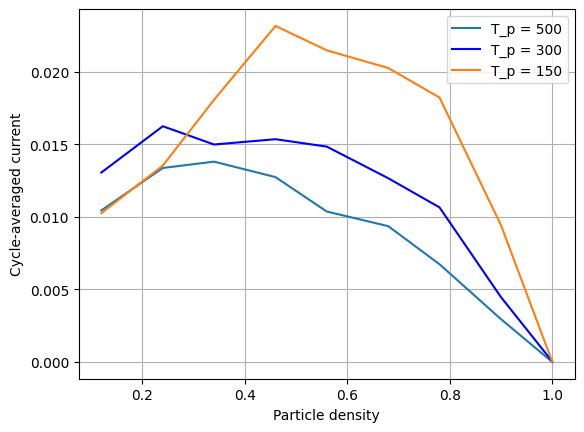

In [ ]:
plt.plot(rho,cur_rho_higherT_p*N_p,label="T_p = 500")
plt.plot(rho,cur_rho*N_p, label="T_p = 300",color="blue")
plt.plot(rho,cur_rho_lowerT_p*N_p,label="T_p = 150")
plt.xlabel("Partikkel tetthet")
plt.ylabel("snitt strømm")
plt.grid()
plt.legend()
plt.show()